In [1]:
import pandas as pd
import numpy as np
import os

In [2]:

import pandas as pd

file_path = r"C:/Users/Admin/Desktop/Tableau/Supply_Chain_Analytics_Project/data/DataCoSupplyChainDataset.csv.csv"

df = pd.read_csv(file_path, encoding="latin1")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
df.head()


Dataset loaded successfully!
Dataset shape: (180519, 53)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [3]:
print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (180519, 53)

First 5 Rows:


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class



Column Names:
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Image', 'Product Name', 'Product Price', 'Product Status', 'shipping

In [4]:
print("Data Types:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum().sort_values(ascending=False).head(15))

print("\nDuplicate Rows:", df.duplicated().sum())

Data Types:
<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  str    
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  str    
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  str    
 9   Customer City                  180519 non-null  str    
 10  Customer Country               180519 non-null  str    
 11  Customer Email                 180519 non-null  str    
 12  Customer Fname               

In [5]:
print("Total Rows:", len(df))
print("Duplicate Rows:", df.duplicated().sum())

Total Rows: 180519
Duplicate Rows: 0


In [6]:
import re

df.columns = [
    re.sub(r"_+", "_",
           re.sub(r"[^a-zA-Z0-9]+", "_", col.strip())
          ).strip("_").lower()
    for col in df.columns
]

print(df.columns.tolist())

['type', 'days_for_shipping_real', 'days_for_shipment_scheduled', 'benefit_per_order', 'sales_per_customer', 'delivery_status', 'late_delivery_risk', 'category_id', 'category_name', 'customer_city', 'customer_country', 'customer_email', 'customer_fname', 'customer_id', 'customer_lname', 'customer_password', 'customer_segment', 'customer_state', 'customer_street', 'customer_zipcode', 'department_id', 'department_name', 'latitude', 'longitude', 'market', 'order_city', 'order_country', 'order_customer_id', 'order_date_dateorders', 'order_id', 'order_item_cardprod_id', 'order_item_discount', 'order_item_discount_rate', 'order_item_id', 'order_item_product_price', 'order_item_profit_ratio', 'order_item_quantity', 'sales', 'order_item_total', 'order_profit_per_order', 'order_region', 'order_state', 'order_status', 'order_zipcode', 'product_card_id', 'product_category_id', 'product_description', 'product_image', 'product_name', 'product_price', 'product_status', 'shipping_date_dateorders', 's

In [7]:
missing = df.isnull().sum()

missing_report = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percentage": (missing / len(df) * 100).round(2)
})

missing_report = missing_report.sort_values(
    "Missing_Percentage", ascending=False
)

display(missing_report[missing_report["Missing_Count"] > 0])

,Missing_Count,Missing_Percentage
product_description,180519,100.00
order_zipcode,155679,86.24
customer_lname,8,0.00
customer_zipcode,3,0.00


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   type                         180519 non-null  str    
 1   days_for_shipping_real       180519 non-null  int64  
 2   days_for_shipment_scheduled  180519 non-null  int64  
 3   benefit_per_order            180519 non-null  float64
 4   sales_per_customer           180519 non-null  float64
 5   delivery_status              180519 non-null  str    
 6   late_delivery_risk           180519 non-null  int64  
 7   category_id                  180519 non-null  int64  
 8   category_name                180519 non-null  str    
 9   customer_city                180519 non-null  str    
 10  customer_country             180519 non-null  str    
 11  customer_email               180519 non-null  str    
 12  customer_fname               180519 non-null  str    
 13  customer_i

In [9]:
print("Dataset Shape:", df.shape)

print("\nAvailable Order and Delivery Columns:")
print([
    col for col in df.columns
    if any(word in col for word in
           ["order", "shipping", "delivery", "date", "quantity", "price"])
])

Dataset Shape: (180519, 53)

Available Order and Delivery Columns:
['days_for_shipping_real', 'benefit_per_order', 'delivery_status', 'late_delivery_risk', 'order_city', 'order_country', 'order_customer_id', 'order_date_dateorders', 'order_id', 'order_item_cardprod_id', 'order_item_discount', 'order_item_discount_rate', 'order_item_id', 'order_item_product_price', 'order_item_profit_ratio', 'order_item_quantity', 'order_item_total', 'order_profit_per_order', 'order_region', 'order_state', 'order_status', 'order_zipcode', 'product_price', 'shipping_date_dateorders', 'shipping_mode']


In [10]:
import os

os.makedirs("../reports", exist_ok=True)

missing_report.to_csv(
    "../reports/missing_values_report.csv",
    index=True
)

print("Missing values report saved successfully.")

Missing values report saved successfully.


In [11]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

Rows: 180519
Columns: 53

Column Names:
['type', 'days_for_shipping_real', 'days_for_shipment_scheduled', 'benefit_per_order', 'sales_per_customer', 'delivery_status', 'late_delivery_risk', 'category_id', 'category_name', 'customer_city', 'customer_country', 'customer_email', 'customer_fname', 'customer_id', 'customer_lname', 'customer_password', 'customer_segment', 'customer_state', 'customer_street', 'customer_zipcode', 'department_id', 'department_name', 'latitude', 'longitude', 'market', 'order_city', 'order_country', 'order_customer_id', 'order_date_dateorders', 'order_id', 'order_item_cardprod_id', 'order_item_discount', 'order_item_discount_rate', 'order_item_id', 'order_item_product_price', 'order_item_profit_ratio', 'order_item_quantity', 'sales', 'order_item_total', 'order_profit_per_order', 'order_region', 'order_state', 'order_status', 'order_zipcode', 'product_card_id', 'product_category_id', 'product_description', 'product_image', 'product_name', 'product_price', 'product

In [12]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
type,180519,4,DEBIT,69295,NaN,NaN,NaN,NaN,NaN,NaN,NaN
days_for_shipping_real,180519.0,NaN,NaN,NaN,3.497654,1.623722,0.0,2.0,3.0,5.0,6.0
days_for_shipment_scheduled,180519.0,NaN,NaN,NaN,2.931847,1.374449,0.0,2.0,4.0,4.0,4.0
benefit_per_order,180519.0,NaN,NaN,NaN,21.974989,104.433526,-4274.97998,7.0,31.52,64.800003,911.799988
sales_per_customer,180519.0,NaN,NaN,NaN,183.107609,120.04367,7.49,104.379997,163.990005,247.399994,1939.98999
delivery_status,180519,4,Late delivery,98977,NaN,NaN,NaN,NaN,NaN,NaN,NaN
late_delivery_risk,180519.0,NaN,NaN,NaN,0.548291,0.497664,0.0,0.0,1.0,1.0,1.0
category_id,180519.0,NaN,NaN,NaN,31.851451,15.640064,2.0,18.0,29.0,45.0,76.0
category_name,180519,50,Cleats,24551,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_city,180519,563,Caguas,66770,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
keywords = [
    "sales", "profit", "order", "category",
    "department", "shipping", "delivery",
    "customer", "quantity", "price", "region"
]

for word in keywords:
    matches = [col for col in df.columns if word in col]
    print(f"{word}: {matches}")

sales: ['sales_per_customer', 'sales']
profit: ['order_item_profit_ratio', 'order_profit_per_order']
order: ['benefit_per_order', 'order_city', 'order_country', 'order_customer_id', 'order_date_dateorders', 'order_id', 'order_item_cardprod_id', 'order_item_discount', 'order_item_discount_rate', 'order_item_id', 'order_item_product_price', 'order_item_profit_ratio', 'order_item_quantity', 'order_item_total', 'order_profit_per_order', 'order_region', 'order_state', 'order_status', 'order_zipcode', 'shipping_date_dateorders']
category: ['category_id', 'category_name', 'product_category_id']
department: ['department_id', 'department_name']
shipping: ['days_for_shipping_real', 'shipping_date_dateorders', 'shipping_mode']
delivery: ['delivery_status', 'late_delivery_risk']
customer: ['sales_per_customer', 'customer_city', 'customer_country', 'customer_email', 'customer_fname', 'customer_id', 'customer_lname', 'customer_password', 'customer_segment', 'customer_state', 'customer_street', 'cust

In [14]:
if "order_status" in df.columns:
    display(df["order_status"].value_counts(dropna=False))
else:
    print("No order_status column found.")

order_status
COMPLETE           59491
PENDING_PAYMENT    39832
PROCESSING         21902
PENDING            20227
CLOSED             19616
ON_HOLD             9804
SUSPECTED_FRAUD     4062
CANCELED            3692
PAYMENT_REVIEW      1893
Name: count, dtype: int64

In [15]:
if {"sales", "order_profit_per_order"}.issubset(df.columns):
    print("Total Sales:", round(df["sales"].sum(), 2))
    print("Total Order Profit:", round(df["order_profit_per_order"].sum(), 2))
else:
    print("Check the actual sales and profit column names from Step 5C.")

Total Sales: 36784735.01
Total Order Profit: 3966902.97


In [16]:
required = {"days_for_shipping_real", "days_for_shipment_scheduled"}

if required.issubset(df.columns):
    df["shipping_delay_days"] = (
        df["days_for_shipping_real"]
        - df["days_for_shipment_scheduled"]
    )

    print("Average Shipping Delay:",
          round(df["shipping_delay_days"].mean(), 2), "days")

    print("\nDelay Distribution:")
    display(df["shipping_delay_days"].describe())
else:
    print("Shipping columns not found. Check Step 5C output.")

Average Shipping Delay: 0.57 days

Delay Distribution:


count    180519.000000
mean          0.565807
std           1.490966
min          -2.000000
25%           0.000000
50%           1.000000
75%           1.000000
max           4.000000
Name: shipping_delay_days, dtype: float64

In [17]:
import matplotlib.pyplot as plt

print("Visualization libraries are ready!")

Visualization libraries are ready!


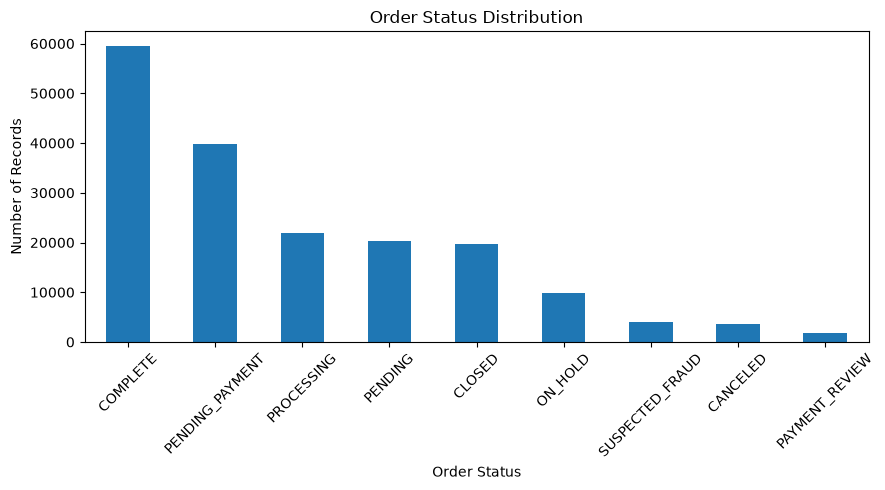

In [18]:
if "order_status" in df.columns:
    status_counts = df["order_status"].value_counts()

    status_counts.plot(
        kind="bar",
        figsize=(9, 5),
        title="Order Status Distribution"
    )

    plt.xlabel("Order Status")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("order_status column not found.")

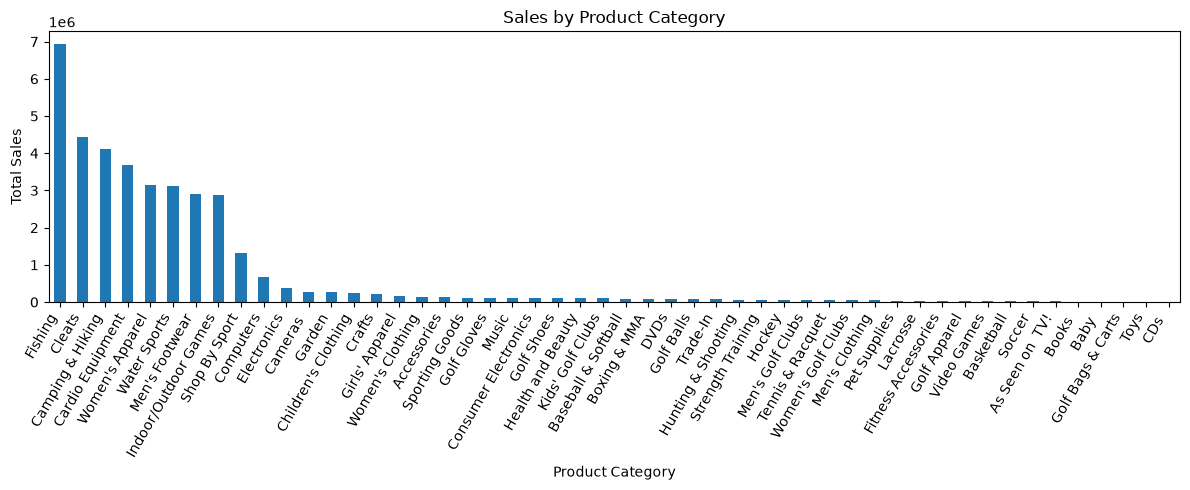

In [19]:
if {"category_name", "sales"}.issubset(df.columns):
    category_sales = (
        df.groupby("category_name")["sales"]
        .sum()
        .sort_values(ascending=False)
    )

    category_sales.plot(
        kind="bar",
        figsize=(12, 5),
        title="Sales by Product Category"
    )

    plt.xlabel("Product Category")
    plt.ylabel("Total Sales")
    plt.xticks(rotation=60, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Required columns not found.")

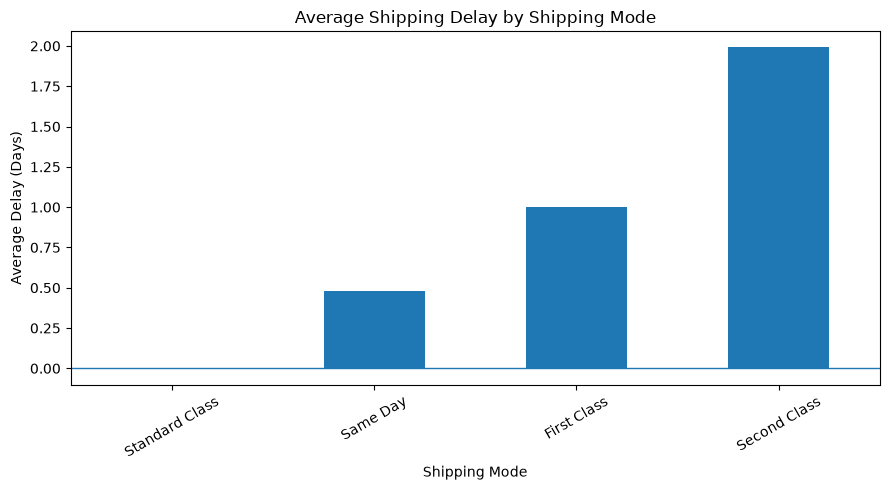

In [20]:
if {"shipping_mode", "shipping_delay_days"}.issubset(df.columns):
    shipping_delay = (
        df.groupby("shipping_mode")["shipping_delay_days"]
        .mean()
        .sort_values()
    )

    shipping_delay.plot(
        kind="bar",
        figsize=(9, 5),
        title="Average Shipping Delay by Shipping Mode"
    )

    plt.xlabel("Shipping Mode")
    plt.ylabel("Average Delay (Days)")
    plt.xticks(rotation=30)
    plt.axhline(0, linewidth=1)
    plt.tight_layout()
    plt.show()
else:
    print("Required columns not found. Check the column names.")

In [21]:
import os

os.makedirs("../images", exist_ok=True)

print("Images folder is ready.")

Images folder is ready.


In [22]:
if {"order_region", "sales"}.issubset(df.columns):
    region_sales = (
        df.groupby("order_region")
        .agg(
            Total_Sales=("sales", "sum"),
            Average_Sales=("sales", "mean"),
            Record_Count=("sales", "size")
        )
        .sort_values("Total_Sales", ascending=False)
    )

    display(region_sales)
else:
    print("Required columns are missing. Check df.columns.")

,Total_Sales,Average_Sales,Record_Count
order_region,,,
Western Europe,5.894381e+06,217.432615,27109
Central America,5.665712e+06,199.912216,28341
South America,2.960881e+06,198.251182,14935
Northern Europe,2.155831e+06,220.162444,9792
Southern Europe,2.047919e+06,217.147579,9431
Oceania,2.016654e+06,198.724300,10148
Southeast Asia,1.932496e+06,202.588905,9539
Caribbean,1.651019e+06,198.487537,8318
West of USA,1.571416e+06,196.599019,7993


In [23]:
if {"category_name", "sales", "order_profit_per_order"}.issubset(df.columns):
    category_performance = (
        df.groupby("category_name")
        .agg(
            Total_Sales=("sales", "sum"),
            Total_Profit=("order_profit_per_order", "sum"),
            Average_Profit=("order_profit_per_order", "mean")
        )
        .sort_values("Total_Profit", ascending=False)
    )

    display(category_performance)
else:
    print("Required columns are missing. Check df.columns.")

,Total_Sales,Total_Profit,Average_Profit
category_name,,,
Fishing,6.929654e+06,756220.767190,43.649106
Cleats,4.431943e+06,494636.919791,20.147323
Camping & Hiking,4.118426e+06,427455.568106,31.135230
Cardio Equipment,3.694843e+06,383011.098485,30.672788
Women's Apparel,3.147800e+06,350421.029567,16.658951
Water Sports,3.113845e+06,325146.960038,20.923228
Indoor/Outdoor Games,2.888994e+06,318451.430554,16.501784
Men's Footwear,2.891758e+06,311902.820214,14.020625
Shop By Sport,1.309522e+06,129813.960315,11.818460


In [24]:
required = {
    "shipping_mode",
    "days_for_shipping_real",
    "days_for_shipment_scheduled"
}

if required.issubset(df.columns):
    shipping_analysis = df.groupby("shipping_mode").agg(
        Average_Actual_Days=("days_for_shipping_real", "mean"),
        Average_Scheduled_Days=("days_for_shipment_scheduled", "mean")
    )

    shipping_analysis["Average_Delay_Days"] = (
        shipping_analysis["Average_Actual_Days"]
        - shipping_analysis["Average_Scheduled_Days"]
    )

    display(shipping_analysis.round(2))
else:
    print("Required shipping columns are missing.")

,Average_Actual_Days,Average_Scheduled_Days,Average_Delay_Days
shipping_mode,,,
First Class,2.00,1.0,1.00
Same Day,0.48,0.0,0.48
Second Class,3.99,2.0,1.99
Standard Class,4.00,4.0,-0.00


In [25]:
import os

os.makedirs("../reports", exist_ok=True)

if "region_sales" in globals():
    region_sales.to_csv("../reports/region_sales.csv")

if "category_performance" in globals():
    category_performance.to_csv(
        "../reports/category_performance.csv"
    )

if "shipping_analysis" in globals():
    shipping_analysis.to_csv(
        "../reports/shipping_performance.csv"
    )

print("Business analysis reports saved successfully!")

Business analysis reports saved successfully!


In [31]:
%pip install sqlalchemy psycopg2-binary

Note: you may need to restart the kernel to use updated packages.


In [4]:
from sqlalchemy import create_engine, text
from getpass import getpass
from urllib.parse import quote_plus

pg_user = input("PostgreSQL username (usually postgres): ")
pg_password = quote_plus(getpass("PostgreSQL password: "))
pg_host = "localhost"
pg_port = "5432"
pg_database = "supply_chain_analytics"

connection_string = (
    f"postgresql+psycopg2://{pg_user}:{pg_password}"
    f"@{pg_host}:{pg_port}/{pg_database}"
)

engine = create_engine(connection_string)

with engine.connect() as connection:
    print(connection.execute(text("SELECT version()")).scalar())

PostgreSQL username (usually postgres):  postgres
PostgreSQL password:  ········


PostgreSQL 18.6 on x86_64-windows, compiled by msvc-19.44.35229, 64-bit


In [28]:
from sqlalchemy import create_engine, text
from getpass import getpass
from urllib.parse import quote_plus

pg_user = input("PostgreSQL username (usually postgres): ")
pg_password = quote_plus(getpass("PostgreSQL password: "))

pg_host = "localhost"
pg_port = "5432"
pg_database = "supply_chain_analytics"

connection_string = (
    f"postgresql+psycopg2://{pg_user}:{pg_password}"
    f"@{pg_host}:{pg_port}/{pg_database}"
)

engine = create_engine(connection_string)

with engine.connect() as connection:
    print("PostgreSQL connected successfully!")
    print(connection.execute(text("SELECT version()")).scalar())

PostgreSQL username (usually postgres):  postgres
PostgreSQL password:  ········


PostgreSQL connected successfully!
PostgreSQL 18.6 on x86_64-windows, compiled by msvc-19.44.35229, 64-bit


In [31]:
df.to_sql(
    name="supply_chain_orders",
    con=engine,
    if_exists="replace",
    index=False,
    chunksize=2000
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [33]:
with engine.connect() as connection:
    result = connection.execute(
        text("SELECT COUNT(*) FROM supply_chain_orders")
    ).scalar()

    print("Rows loaded:", result)

Rows loaded: 180519


In [3]:
# tableau connection
import os

os.makedirs("../tableau", exist_ok=True)

df.to_csv(
    "../tableau/supply_chain_orders.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Tableau CSV file exported successfully!")

Tableau CSV file exported successfully!
